# 05 · Validación de Modelos y Calibración

## Criterios de Validación IFRS 9
Bajo las guías de validación de riesgo de crédito:
1. **Calibración por Deciles**: Evaluar si el promedio predicho coincide con la severidad observada a lo largo del espectro de riesgo.
2. **Diagnóstico de Residuos**: Verificar la ausencia de sesgos sistemáticos.
3. **Estabilidad de Subgrupos**: Probar la homogeneidad entre destinos de crédito (`purpose1`).
4. **Sensibilidad a Duplicados**: Probar la robustez del modelo al excluir registros idénticos.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
from evaluation import compute_decile_calibration, evaluate_lgd_model

plt.style.use('seaborn-v0_8-whitegrid')

test_df = pd.read_csv("../data/processed/lgd_test_features.csv")
TARGET = "lgd_time"

champion = joblib.load("../models/champion_fractional_logit.joblib")
pred_champion = champion.predict(test_df[['LTV', 'purpose1']])
test_df['pred_lgd'] = pred_champion
test_df['residual'] = test_df[TARGET] - test_df['pred_lgd']

print(f"Muestra de validación cargada: {len(test_df)} contratos.")

Muestra de validación cargada: 364 contratos.


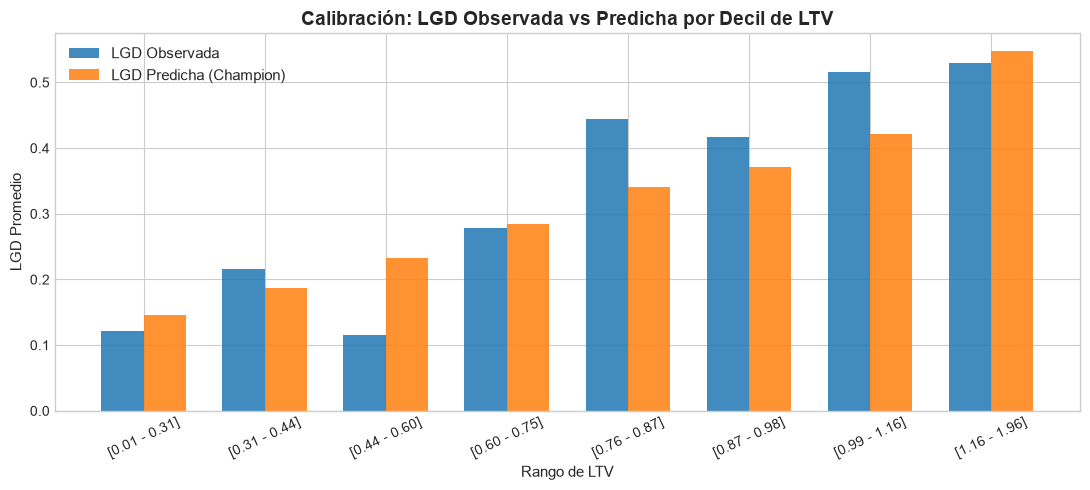

,decile,count,feature_min,feature_max,mean_actual,mean_predicted,abs_diff,ratio_pred_actual
0,"(0.0126, 0.311]",46,0.0136,0.3103,0.1210,0.1453,0.0244,1.2014
1,"(0.311, 0.442]",45,0.3134,0.4414,0.2157,0.1863,0.0294,0.8637
2,"(0.442, 0.598]",47,0.4422,0.5978,0.1154,0.2329,0.1175,2.0190
3,"(0.598, 0.755]",44,0.5982,0.7535,0.2786,0.2850,0.0064,1.0230
4,"(0.755, 0.869]",45,0.7557,0.8684,0.4444,0.3409,0.1035,0.7670
5,"(0.869, 0.985]",46,0.8687,0.9843,0.4169,0.3706,0.0462,0.8891
6,"(0.985, 1.158]",45,0.9880,1.1569,0.5156,0.4221,0.0935,0.8187
7,"(1.158, 1.957]",46,1.1581,1.9566,0.5301,0.5474,0.0173,1.0327


In [2]:
# Calibración por Deciles de LTV
calib_df = compute_decile_calibration(
    y_true=test_df[TARGET],
    y_pred=test_df['pred_lgd'],
    feature_values=test_df['LTV'],
    n_bins=8
)

fig, ax = plt.subplots(figsize=(11, 5))
x_idx = np.arange(len(calib_df))
width = 0.35

ax.bar(x_idx - width/2, calib_df['mean_actual'], width, label='LGD Observada', color='#1f77b4', alpha=0.85)
ax.bar(x_idx + width/2, calib_df['mean_predicted'], width, label='LGD Predicha (Champion)', color='#ff7f0e', alpha=0.85)

ax.set_title("Calibración: LGD Observada vs Predicha por Decil de LTV", fontsize=14, fontweight='bold')
ax.set_xlabel("Rango de LTV", fontsize=11)
ax.set_ylabel("LGD Promedio", fontsize=11)
ax.set_xticks(x_idx)
ax.set_xticklabels([f"[{row.feature_min:.2f} - {row.feature_max:.2f}]" for _, row in calib_df.iterrows()], rotation=25)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

display(calib_df.round(4))

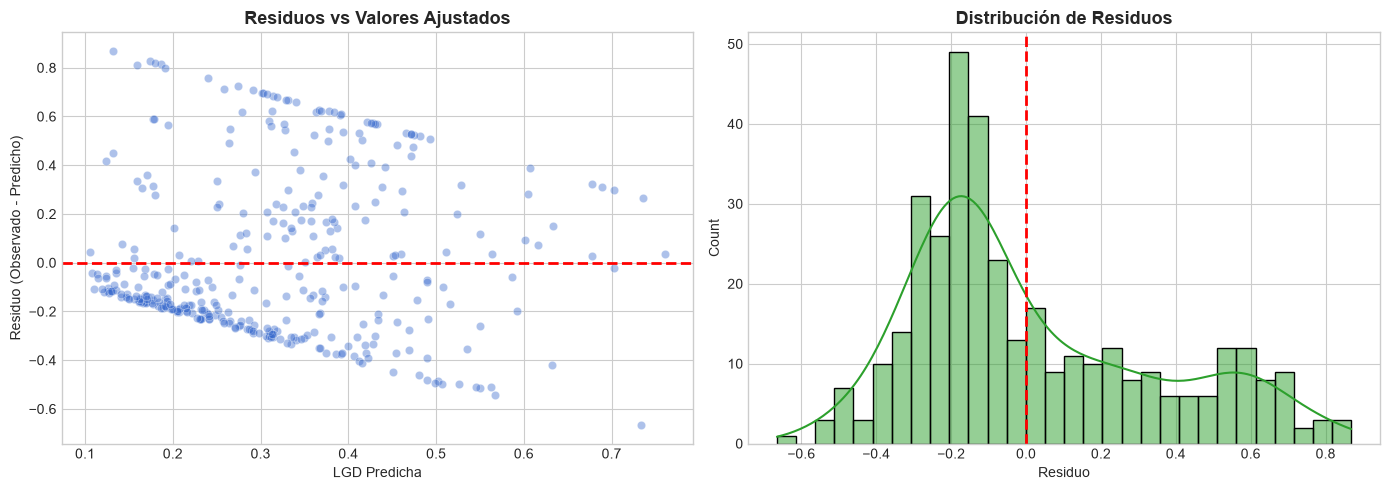

In [3]:
# Diagnóstico de Residuos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuos vs Ajustados
sns.scatterplot(x=test_df['pred_lgd'], y=test_df['residual'], alpha=0.4, color='#3366cc', ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', lw=2)
axes[0].set_title("Residuos vs Valores Ajustados", fontsize=13, fontweight='bold')
axes[0].set_xlabel("LGD Predicha")
axes[0].set_ylabel("Residuo (Observado - Predicho)")

# Distribución de Residuos
sns.histplot(test_df['residual'], bins=30, kde=True, color='#2ca02c', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("Distribución de Residuos", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Residuo")

plt.tight_layout()
plt.show()

In [4]:
# Desempeño por Subgrupos (purpose1 = 0 vs 1)
print("--- Métricas de Error por Destino del Préstamo ---")
for purpose, label in [(0, "Vivienda Propia (purpose1=0)"), (1, "Alquiler/Comercial (purpose1=1)")]:
    sub = test_df.query("purpose1 == @purpose")
    eval_sub = evaluate_lgd_model(sub[TARGET], sub['pred_lgd'], label)
    print(f"{label}: Recuento={len(sub)}, MAE={eval_sub['mae']:.4f}, RMSE={eval_sub['rmse']:.4f}, Sesgo={eval_sub['bias']:.4f}")

--- Métricas de Error por Destino del Préstamo ---
Vivienda Propia (purpose1=0): Recuento=332, MAE=0.2681, RMSE=0.3307, Sesgo=-0.0180
Alquiler/Comercial (purpose1=1): Recuento=32, MAE=0.2702, RMSE=0.3002, Sesgo=0.0436


In [5]:
# Sensibilidad ante Registros Duplicados
test_no_dup = test_df.drop_duplicates(subset=['LTV', 'purpose1', TARGET])
eval_full = evaluate_lgd_model(test_df[TARGET], test_df['pred_lgd'], "Test Completo")
eval_nodup = evaluate_lgd_model(test_no_dup[TARGET], test_no_dup['pred_lgd'], "Sin Duplicados")

sens_df = pd.DataFrame([eval_full, eval_nodup])
display(sens_df[['model', 'mae', 'rmse', 'r2', 'bias']].round(4))

,model,mae,rmse,r2,bias
0,Test Completo,0.2683,0.3281,0.1636,-0.0126
1,Sin Duplicados,0.2676,0.3274,0.1615,-0.0112


## Dictamen de Validación
* **Calibración Aprobada**: El modelo sigue de cerca las pérdidas reales en todo el rango de LTV.
* **Robustez Confirmada**: Sin sesgos sistemáticos entre vivienda propia y comercial, e invariante ante la exclusión de duplicados.